# Convective drying – energy demand model

*Drying › Convective drying* (manuscript Fig. 1)

**Examples** (Fig. 1). All use the same model; the examples change nothing in the equations.
| Process | Products |
|---|---|
| Spray drying | milk powder, coffee powder, egg powder, whey protein |
| Granulate drying | plastic granulates, pharmaceutical granules, silica gel |
| Ring drying | soya products, casein, Epsom salt, calcium carbonate, paper sludge |
| Flash drying | starch powder, potato powder, sauce powder, silicates |

Air is heated from $T_0$ to the drying temperature $T_1$ at constant humidity, takes up the water removed from the product and leaves the dryer at $T_2$, $x_2$. The outlet air is cooled to $T_3$: sensibly to its dew point, then with condensation (manuscript section *Convective drying*, Fig. 3). Moist air: $h(T,x)=c_{p,air}T+x\,(h_{v,0}+c_{p,vapor}T)$ in `process_models/humid_air.py`.

$$\dot Q_{heating}=\dot m_{air}\,\big(h(T_1,x_1)-h(T_0,x_0)\big)\quad(3)\qquad \dot m_{water}=\dot m_{product}\,(w_1-w_2)\quad(4)\qquad x_2=x_1+\frac{\dot m_{water}}{\dot m_{air}}\quad(5)$$
$$T_2=\frac{T_1\,(c_{p,air}+x_1c_{p,vapor})+h_{v,water}\,(x_1-x_2)-\frac{U A\,(T_{average}-T_{amb})}{\dot m_{air}}}{c_{p,air}+x_2\,c_{p,vapor}}\quad(6)$$
$$\dot Q_{dew}=\dot m_{air}\,(h_{outlet}-h_{dew})\quad(7)\qquad \dot Q_{latent}=\dot m_{air}\,(h_{dew}-h_{return})\quad(8)\qquad \dot Q_{cooling}=\dot Q_{dew}+\dot Q_{latent}\quad(9)$$

This notebook holds no formulas of its own: it imports **`model.py`**, the model the app runs.

1. Example calculation
2. Figures and simplified P&ID (saved as `pid.svg`)
3. Validation against the manuscript and consistency checks
4. Comparison with an existing implementation

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle, FancyBboxPatch, Polygon
from IPython.display import display, Markdown

try:
    import process_models
except ImportError:            # not installed: use the copy in this repository
    import sys
    sys.path.insert(0, str(Path.cwd().parents[1]))   # .../process_models (the folder holding the package)

from process_models import PROCESSES, run_process
from process_models.convective_drying.model import MODEL, calculate

KEY = MODEL.key

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})


def show(res, audit):
    """Input table, results and stream data of one run."""
    display(Markdown("**Inputs** (required / optional, source of each value)"))
    display(pd.DataFrame(audit))
    for w in res.warnings:
        print("WARNING:", w)
    display(Markdown("**Results**"))
    display(pd.DataFrame(res.summary()))
    display(Markdown("**Stream data** (what the app hands to the pinch analysis)"))
    display(pd.DataFrame(res.stream_table()))


print(f"{MODEL.name} v{MODEL.version} | processes found by the app: {list(PROCESSES)}")

Convective drying v1.0 | processes found by the app: ['autoclaving', 'conductive_drying', 'continuous_bath_heating', 'continuous_heating_of_fluid', 'convective_drying', 'thermal_phase_change']


## 1  Example calculation
Spray dryer with the inputs of the manuscript's validation case (p. 17): air 55.7 kg/s, $T_0$ 15 °C,
$x_0$ 6.43 g/kg, drying temperature 210 °C, water removed 1.6 kg/s, $T_3$ 15 °C. The manuscript gives only the
water removed; the model needs product flow and moisture contents, and only their product
$\dot m_{product}(w_1-w_2)$ = 1.6 kg/s enters, so the split below is arbitrary. Only required inputs, no losses.

In [2]:
SPRAY = dict(product_flow_kg_h=1.6 * 3600 / 0.5, w1=0.55, w2=0.05,      # 1.6 kg/s water removed
             air_flow_kg_h=55.7 * 3600, T0=15, T1=210, x0_g_kg=6.43)
result, audit = run_process(KEY, **SPRAY)
show(result, audit)

**Inputs** (required / optional, source of each value)

,Symbol,Input,Value,Unit,Type,Source,Manuscript / note
0,m_product,Product mass flow rate,"11,520.000",kg/h,required,user input,"Sect. 'Convective drying', input list"
1,w1,Initial moisture content of the product,0.550,kg/kg,required,user input,"Sect. 'Convective drying', input list | Eq. (4): water removed = m_product * (w1 - w2)."
2,w2,Final moisture content of the product,0.050,kg/kg,required,user input,"Sect. 'Convective drying', input list"
3,m_air,Drying air mass flow rate (dry air),"200,520.000",kg/h,required,user input,"Sect. 'Convective drying', input list"
4,T0,Initial air temperature,15.000,degC,required,user input,"Sect. 'Convective drying', input list"
5,T1,Drying air temperature,210.000,degC,required,user input,"Sect. 'Convective drying', input list"
6,"x0, x1",Absolute humidity of the air (x1 = x0),6.430,g/kg,required,user input,"Sect. 'Convective drying', input list"
7,T3,Air temperature after cooling,15.000,degC,optional,"= T0, not from manuscript","Eq. (8), Fig. 3 | Not in the input list; default = T0."
8,U*A,UA-value of the dryer (heat losses),0.000,W/K,optional,default,"Eq. (6), Fig. 3 | Not in the input list; 0 = no losses."
9,T_amb,Ambient temperature,20.000,degC,optional,default,Eq. (6)


**Results**

,Quantity,Symbol,Value,Unit,Manuscript ref.
0,HEATING DEMAND (air heater),"m_air*(h(T1,x1) - h(T0,x0))","11,056.570",kW,Eq. (3)
1,Water removed from the product,m_product*(w1 - w2),"5,760.000",kg/h,Eq. (4)
2,Outlet air humidity,x2 = x1 + m_water/m_air,35.155,g/kg,Eq. (5)
3,Outlet air temperature,T2,132.472,degC,Eq. (6)
4,Dew point of the outlet air,T_dew(x2),34.372,degC,-
5,Sensible cooling to the dew point,m_air*(h_outlet - h_dew),"5,854.291",kW,Eq. (7)
6,Latent cooling (condensation),m_air*(h_dew - h_return),"4,611.454",kW,Eq. (8)
7,COOLING DEMAND (outlet air),Q_dew + Q_latent,"10,465.746",kW,Eq. (9)
8,Condensate,m_air*(x2 - x3),"4,918.935",kg/h,-


**Stream data** (what the app hands to the pinch analysis)

,stream,type,T_supply_degC,T_target_degC,CP_kW_per_K,Q_kW
0,air heating,cold,15.000,210.000,56.700,"11,056.570"
1,"exhaust air, sensible",hot,132.472,34.372,59.676,"5,854.291"
2,"exhaust air, condensation",hot,34.372,15.000,238.050,"4,611.454"


## 2  Figures and simplified P&ID

In [3]:
def plot_demand_breakdown(res):
    """Every kW quantity of the results table; totals dark."""
    rows = [r for r in res.summary() if r["Unit"] == "kW"][::-1]
    fig, ax = plt.subplots(figsize=(9, 0.45 * len(rows) + 1.4))
    colors = ["#333333" if r["Quantity"].split(" (")[0].isupper() else "#4c78a8" for r in rows]
    bars = ax.barh([r["Quantity"] for r in rows], [r["Value"] for r in rows], color=colors)
    for b, r in zip(bars, rows):
        ax.annotate(f"{r['Value']:,.1f} kW", (b.get_width(), b.get_y() + b.get_height() / 2),
                    xytext=(4, 0), textcoords="offset points", va="center", fontsize=8)
    ax.set(xlabel="Thermal power [kW]", title=f"Energy demand: {MODEL.name}")
    ax.margins(x=0.2)
    fig.tight_layout()
    return fig


def plot_stream_data(res):
    """Streams handed to the pinch analysis, stacked by heat flow: cold blue, hot red."""
    fig, ax = plt.subplots(figsize=(8, 4.6))
    q, temps = {"cold": 0.0, "hot": 0.0}, []
    for s in res.stream_table():
        q0 = q[s["type"]]
        q[s["type"]] = q1 = q0 + s["Q_kW"]
        color = "tab:blue" if s["type"] == "cold" else "tab:red"
        ax.annotate("", xy=(q1, s["T_target_degC"]), xytext=(q0, s["T_supply_degC"]),
                    arrowprops=dict(arrowstyle="-|>", color=color, lw=2, mutation_scale=14))
        ax.text((q0 + q1) / 2, (s["T_supply_degC"] + s["T_target_degC"]) / 2, "  " + s["stream"],
                color=color, fontsize=8, va="bottom")
        temps += [s["T_supply_degC"], s["T_target_degC"]]
    qmax = max(q.values()) or 1.0
    ax.set_xlim(-0.02 * qmax, 1.1 * qmax)
    ax.set_ylim(min(temps) - 10, max(temps) + 10)
    ax.set(xlabel="Heat flow [kW]", ylabel="Temperature [degC]", title="Stream data (cold: blue, hot: red)")
    fig.tight_layout()
    return fig


def plot_sensitivity(res, sweeps):
    """One-at-a-time sensitivity of the heating and cooling demand."""
    fig, axes = plt.subplots(1, len(sweeps), figsize=(6 * len(sweeps), 4), squeeze=False)
    for ax, (param, grid, xlabel) in zip(axes[0], sweeps):
        rows = []
        for x in grid:
            try:
                r = calculate({**res.inputs, param: float(x)})
                rows.append((x, r.Q_heating, r.Q_cooling))
            except ValueError:
                continue
        xs, qh, qc = zip(*rows)
        ax.plot(xs, qh, label="heating demand")
        if any(qc):
            ax.plot(xs, qc, label="cooling demand")
        ax.axvline(res.inputs[param], color="grey", ls="--", lw=0.8)
        ax.set(xlabel=xlabel, ylabel="Thermal power [kW]")
        ax.legend(fontsize=8)
    fig.suptitle("Sensitivity (one parameter varied, all others fixed)")
    fig.tight_layout()
    return fig



SWEEPS = [("T1", np.linspace(120, 260, 29), "Drying air temperature T1 [degC]"),
          ("air_flow_kg_h", np.linspace(0.8, 1.6, 33) * SPRAY["air_flow_kg_h"], "Air mass flow [kg/h]")]

In [4]:
class Sketch:
    """Small drawing kit for the simplified P&IDs (ISA-5.1 style tags)."""

    def __init__(self, ax, lw=1.8):
        self.ax, self.lw = ax, lw

    def line(self, xs, ys, ls="-", lw=None, color="k"):
        self.ax.plot(xs, ys, ls=ls, lw=lw or self.lw, color=color, solid_capstyle="butt", zorder=2)

    def arrow(self, x0, y0, x1, y1, color="k"):
        self.ax.annotate("", xy=(x1, y1), xytext=(x0, y0), zorder=3,
                         arrowprops=dict(arrowstyle="-|>", lw=self.lw, color=color, mutation_scale=14))

    def text(self, x, y, s, **kw):
        kw.setdefault("fontsize", 9); kw.setdefault("ha", "center"); kw.setdefault("va", "center")
        self.ax.text(x, y, s, **kw)

    def hx(self, x, y, r=0.55):
        """Heat exchanger: circle with zigzag."""
        self.ax.add_patch(Circle((x, y), r, fc="white", ec="k", lw=1.6, zorder=4))
        self.ax.plot(np.linspace(x - 0.42, x + 0.42, 7), y + 0.14 * np.array([0, 1, -1, 1, -1, 1, 0]),
                     color="k", lw=1.3, zorder=5)

    def box(self, x, y, w, h, s="", fc="#eef3f8", rounded=False, fontsize=8.5):
        patch = (FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.3", fc=fc, ec="k", lw=1.6, zorder=3)
                 if rounded else Rectangle((x, y), w, h, fc=fc, ec="k", lw=1.6, zorder=3))
        self.ax.add_patch(patch)
        if s:
            self.text(x + w / 2, y + h / 2, s, fontsize=fontsize, zorder=4)

    def pump(self, x, y, tag, r=0.45):
        """Pump or fan."""
        self.ax.add_patch(Circle((x, y), r, fc="white", ec="k", lw=1.6, zorder=4))
        self.ax.add_patch(Polygon([(x - .2, y - .28), (x - .2, y + .28), (x + .3, y)], fc="k", zorder=5))
        self.text(x, y - r - 0.3, tag)

    def bubble(self, x, y, tag, num, value=None, r=0.42, below=False):
        """Instrument bubble with tag, loop number and the value it measures or controls."""
        self.ax.add_patch(Circle((x, y), r, fc="white", ec="k", lw=1.4, zorder=5))
        self.text(x, y + 0.1, tag, fontsize=8.5, fontweight="bold", zorder=6)
        self.text(x, y - 0.16, num, fontsize=8, zorder=6)
        if value is not None:
            self.text(x, y - r - 0.25 if below else y + r + 0.25, value, color="firebrick", fontweight="bold")

    def valve_h(self, x, y):
        """Control valve on a horizontal line, actuator on top."""
        for sgn in (+1, -1):
            self.ax.add_patch(Polygon([(x + sgn * .22, y + .25), (x + sgn * .22, y - .25), (x, y)],
                                      fc="white", ec="k", lw=1.4, zorder=5))
        self.ax.plot([x, x], [y, y + 0.45], color="k", lw=1.2, zorder=5)
        self.ax.add_patch(Circle((x, y + 0.65), 0.2, fc="white", ec="k", lw=1.2, zorder=5))

    def valve_v(self, x, y, side=+1):
        """Control valve on a vertical line, actuator to the side."""
        for sgn in (+1, -1):
            self.ax.add_patch(Polygon([(x - .25, y + sgn * .22), (x + .25, y + sgn * .22), (x, y)],
                                      fc="white", ec="k", lw=1.4, zorder=5))
        self.ax.plot([x, x + side * 0.45], [y, y], color="k", lw=1.2, zorder=5)
        self.ax.add_patch(Circle((x + side * 0.65, y), 0.2, fc="white", ec="k", lw=1.2, zorder=5))

    def signal(self, xs, ys):
        self.line(xs, ys, ls=":", lw=1.1)


FOOT = "Simplified P&ID (ISA-5.1 style tags), generated from the demand model - not for construction."


def new_pid(title, ymin=-1.3, ymax=9.6):
    fig, ax = plt.subplots(figsize=(16, 16 * (ymax - ymin) / 20))
    ax.set_xlim(0, 20); ax.set_ylim(ymin, ymax); ax.set_aspect("equal"); ax.axis("off")
    ax.set_title(title, fontsize=12)
    return fig, ax, Sketch(ax)


def footer(ax, s):
    ax.text(0.3, ax.get_ylim()[0] + 0.05, s, fontsize=8.5, color="dimgrey", va="bottom")

In [5]:
def draw_pid(res):
    """Simplified P&ID of a spray dryer with air heater and exhaust air cooler."""
    v = res.inputs
    fig, ax, s = new_pid("Convective drying (spray dryer) - simplified P&ID")
    ya = 2.0
    # ---- air: ambient, fan, heater, up to the dryer top -------------------------------------
    s.box(0.3, ya - 0.7, 1.8, 1.4, f"Ambient air\nT0 = {v['T0']:.0f} degC\nx0 = {v['x0_g_kg']:.2f} g/kg", rounded=True)
    s.line([2.1, 2.55], [ya, ya]); s.pump(3.0, ya, "F-101 Fan")
    s.line([3.45, 4.05], [ya, ya]); s.hx(4.6, ya)
    s.text(4.6, ya - 1.05, f"E-101 Air heater\nQ = {res.Q_heating:,.1f} kW")
    s.line([4.6, 4.6], [ya + 0.55, ya + 0.8]); s.text(4.6, ya + 0.95, "hot utility", fontsize=7.5)
    s.line([5.15, 6.4], [ya, ya]); s.line([6.4, 6.4], [ya, 7.6]); s.line([6.4, 8.2], [7.6, 7.6]); s.line([8.2, 8.2], [7.6, 7.2])
    s.arrow(6.4, 4.6, 6.4, 5.0)
    s.signal([5.6, 5.6], [ya, ya + 0.58]); s.bubble(5.6, ya + 1.0, "TIC", "101", f"{v['T1']:.0f} degC")
    # ---- dryer --------------------------------------------------------------------------------
    ax.add_patch(Rectangle((7.5, 3.4), 2.0, 3.8, fc="white", ec="k", lw=1.6, zorder=3))
    ax.add_patch(Polygon([(7.5, 3.4), (9.5, 3.4), (8.7, 2.3), (8.3, 2.3)], fc="white", ec="k", lw=1.6, zorder=3))
    s.text(8.5, 5.3, "D-101\nSpray dryer", zorder=4)
    # ---- feed ---------------------------------------------------------------------------------
    s.box(0.3, 7.6, 1.8, 1.2, f"T-101 Feed\n{v['product_flow_kg_h']:,.0f} kg/h\nw1 = {v['w1']:.2f}")
    s.line([2.1, 2.55], [8.2, 8.2]); s.pump(3.0, 8.2, "P-101")
    s.line([3.45, 8.8], [8.2, 8.2]); s.line([8.8, 8.8], [8.2, 7.2]); s.arrow(6.8, 8.2, 7.2, 8.2)
    # ---- dried product -----------------------------------------------------------------------
    s.line([8.5, 8.5], [2.3, 1.0]); s.line([8.5, 13.6], [1.0, 1.0]); s.arrow(11.5, 1.0, 11.9, 1.0)
    s.box(13.6, 0.4, 2.0, 1.2, f"T-102 Product\nw2 = {v['w2']:.2f}")
    # ---- exhaust air: cooler / condenser -------------------------------------------------------
    s.line([9.5, 11.65], [5.6, 5.6]); s.arrow(9.9, 5.6, 10.3, 5.6); s.hx(12.2, 5.6)
    s.line([12.2, 12.2], [6.15, 6.4]); s.text(12.2, 6.55, "cold utility", fontsize=7.5)
    s.text(12.85, 7.3, f"E-102 Exhaust air cooler\nQ = {res.Q_cooling:,.1f} kW\n(sensible {res.Q_dew:,.0f} + latent {res.Q_latent:,.0f} kW)",
           ha="left")
    s.line([12.2, 12.2], [5.05, 4.3]); s.arrow(12.2, 4.6, 12.2, 4.25)
    s.text(12.2, 3.9, f"condensate\n{res.condensate_kg_h:,.0f} kg/h", fontsize=7.5)
    s.line([12.75, 15.6], [5.6, 5.6]); s.arrow(14.6, 5.6, 15.0, 5.6)
    s.box(15.6, 5.0, 2.0, 1.2, f"Air out\nT3 = {v['T_return']:.0f} degC")
    s.signal([10.9, 10.9], [5.6, 6.18]); s.bubble(10.9, 6.6, "TI", "102", f"T2 = {res.T2:.1f} degC")
    footer(ax, FOOT + " Drying per Eq. (6) with the dryer's UA-value; heat recovery is not modelled.\n"
           f"m_air = {v['air_flow_kg_h']:,.0f} kg/h, water removed = {res.water_removed_kg_h:,.0f} kg/h, "
           f"x2 = {res.x2 * 1000:.1f} g/kg, dew point {res.T_dew:.1f} degC")
    return fig

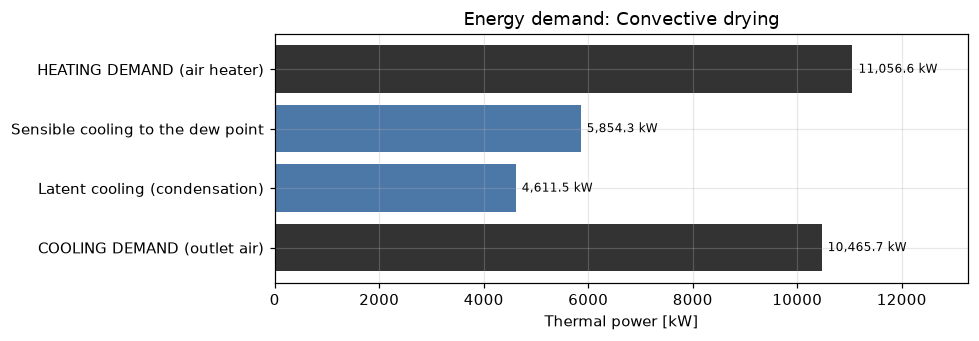

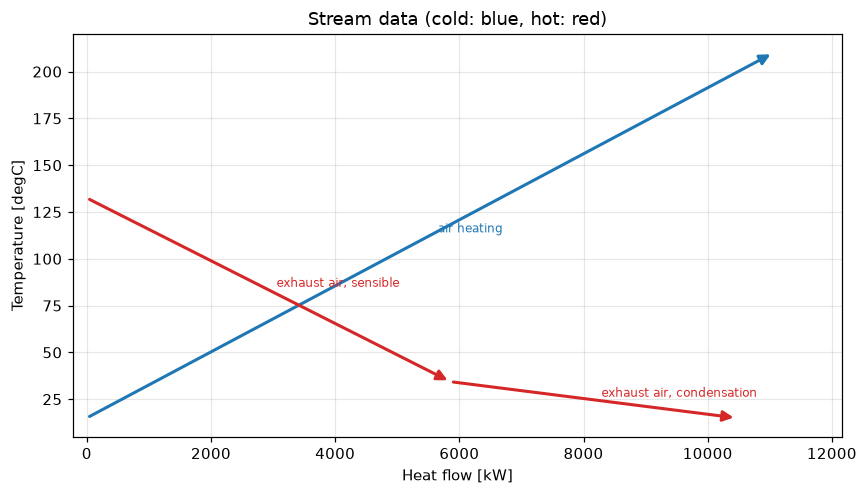

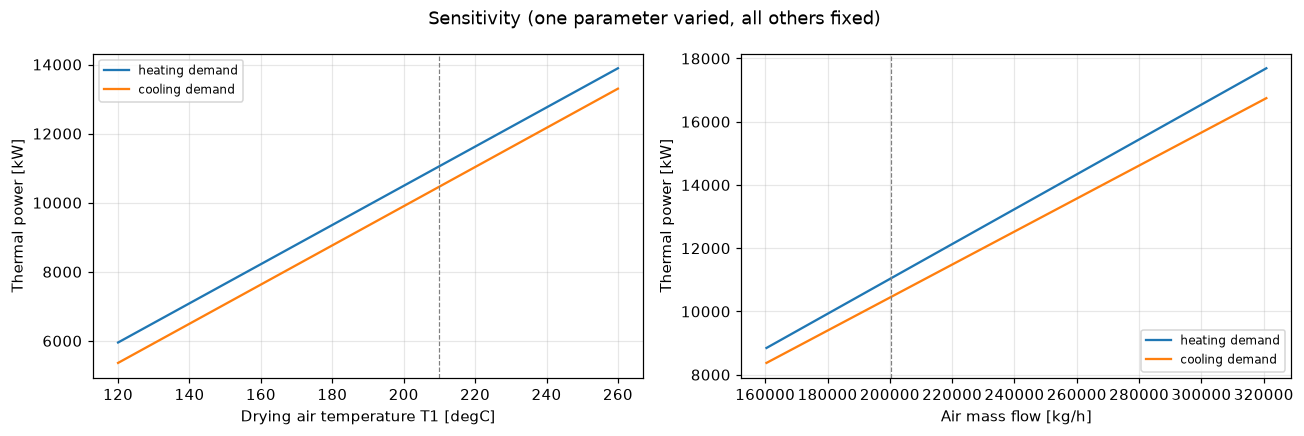

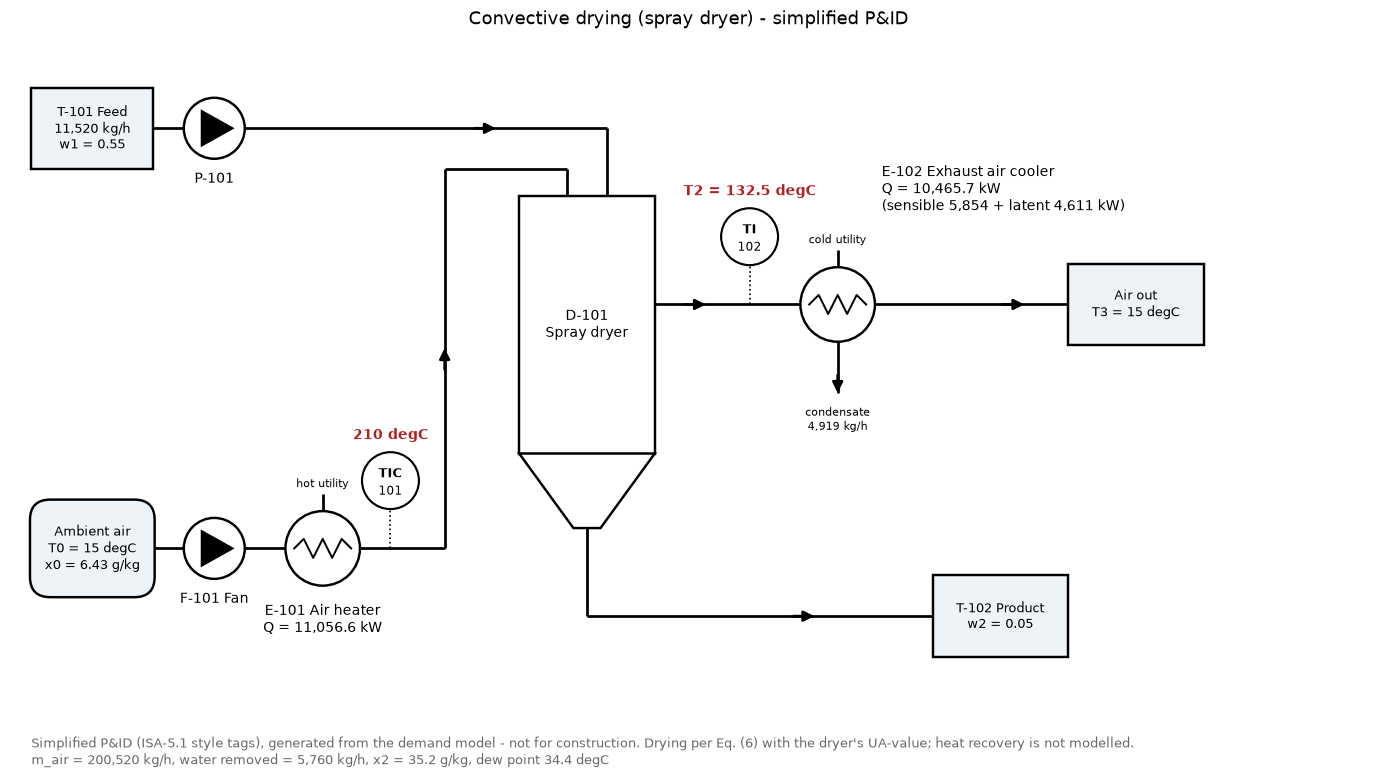

In [6]:
for fig in (plot_demand_breakdown(result), plot_stream_data(result), plot_sensitivity(result, SWEEPS)):
    plt.show()

fig = draw_pid(result)
fig.savefig("pid.svg", bbox_inches="tight")   # P&ID of the example, kept next to model.py
plt.show()

## 3  Validation against the manuscript
Spray dryer, measured data of a dairy (reference [23]), manuscript p. 17, Table 1:

| | Model (manuscript) | Reference |
|---|---|---|
| Energy demand | 10,915.81 kW | 11,134.43 kW |
| Outlet temperature | 77.9 °C | 78.1 °C |
| Pinch temperature | 73.1 °C | 73.2 °C |

**Points found in the manuscript (please check):**
1. **Energy demand:** 10,915.81 kW is exactly 55.7 kg/s · 1.005 kJ/(kg K) · 195 K, i.e. dry air only. Eq. (3) with
   $h(T,x)$ also heats the vapour in the air and gives 11,056.6 kW, **0.70 %** below the reference (manuscript: 2.00 %).
2. **Outlet temperature:** Eq. (6) without losses gives 132.5 °C, not 77.9 °C. The manuscript must have used a
   UA-value of the dryer (Fig. 3), which it does not state: about 26.3 kW/K reproduces 77.9 °C (below).
3. **Outlet humidity:** Eq. (5) with 1.6 kg/s gives 35.16 g/kg; the reference states 34.35 g/kg.
4. Not stated: whether $\dot m_{air}$ is dry or moist air (here: dry air), the basis of $w$ (Eq. (4) is exact on a
   dry basis with the dry-solids flow), and $T_{average}$ in Eq. (6) (here: mean of $T_1$ and $T_2$).
5. The pinch temperature comes from the pinch analysis of the app, not from this model.

In [7]:
REF = dict(Q_model=10915.81, Q_ref=11134.43, RMSE=218.62, T2_model=77.9, T2_ref=78.1, x2_ref=34.35)
from process_models import humid_air as ha


def ua_for(res, T2):
    # Eq. (6) solved for the UA-value [kW/K] that gives the outlet temperature T2
    v, m = res.inputs, res.inputs["air_flow_kg_h"] / 3600
    num = v["T1"] * (ha.CP_AIR + res.x1 * ha.CP_VAPOR) + ha.H_V0 * (res.x1 - res.x2) - T2 * (ha.CP_AIR + res.x2 * ha.CP_VAPOR)
    return m * num / ((v["T1"] + T2) / 2 - v["T_amb"])


UA = ua_for(result, REF["T2_model"])
with_ua, _ = run_process(KEY, **SPRAY, UA_W_K=UA * 1000)
display(pd.DataFrame([
    ("Energy demand [kW]", result.Q_heating, REF["Q_model"], REF["Q_ref"]),
    ("Energy demand, dry air cp 1.005 only [kW]", 55.7 * 1.005 * (210 - 15), REF["Q_model"], REF["Q_ref"]),
    ("Outlet temperature, no losses [degC]", result.T2, REF["T2_model"], REF["T2_ref"]),
    (f"Outlet temperature, UA = {UA:.1f} kW/K [degC]", with_ua.T2, REF["T2_model"], REF["T2_ref"]),
    ("Outlet humidity [g/kg]", result.x2 * 1000, None, REF["x2_ref"]),
], columns=["Quantity", "This model", "Manuscript model", "Reference"]))
print(f"This model vs. reference: {(result.Q_heating - REF['Q_ref']) / REF['Q_ref']:+.2%}")
dev = abs(REF["Q_model"] - REF["Q_ref"])
print(f"Manuscript: |{REF['Q_model']} - {REF['Q_ref']}| = {dev:.2f} kW (RMSE {REF['RMSE']}), {dev / REF['Q_model']:.2%} of the model value")

# ---- consistency checks -----------------------------------------------------------------------
assert abs(55.7 * 1.005 * 195 - REF["Q_model"]) < 0.01                       # point 1
assert abs(ha.enthalpy(result.T2, result.x2) - result.h1) < 1e-9             # Eq. (6) without losses: isenthalpic
assert abs(with_ua.T2 - REF["T2_model"]) < 1e-9                              # UA reproduces 77.9 degC
assert abs(result.Q_cooling - result.Q_dew - result.Q_latent) < 1e-9         # Eq. (9)
st = result.stream_table()
assert abs(sum(s["Q_kW"] for s in st if s["type"] == "hot") - result.Q_cooling) < 1e-6
print("All consistency checks passed.")

,Quantity,This model,Manuscript model,Reference
0,Energy demand [kW],"11,056.570","10,915.810","11,134.430"
1,"Energy demand, dry air cp 1.005 only [kW]","10,915.807","10,915.810","11,134.430"
2,"Outlet temperature, no losses [degC]",132.472,77.900,78.100
3,"Outlet temperature, UA = 26.3 kW/K [degC]",77.900,77.900,78.100
4,Outlet humidity [g/kg],35.155,NaN,34.350


This model vs. reference: -0.70%
Manuscript: |10915.81 - 11134.43| = 218.62 kW (RMSE 218.62), 2.00% of the model value
All consistency checks passed.


## 4  Comparison with an existing implementation
Not possible yet: the original notebook (`continuous_heating_of_fluid/energy_demand_models_notebook_1.ipynb`) only lists
this process as *planned*; the legacy `classes.SprayDryerModel`, `AirConditioner` and `AirCooler` it mentions are not
in the repository.